# CAPM vs Fama-French Three-Factor Model

This section investigates the sources of historical returns for Kappa Foundation's recommended growth portfolio and two selected stocks, AAPL and CVX.

We compare two models:

**CAPM (market-only regression)**

$$
R_i-R_f=\alpha_i+\beta_{i,M}(R_M-R_f)+\varepsilon_i
$$

**Fama-French Three-Factor Model (FF3)**

$$
R_i-R_f=\alpha_i+\beta_{i,M}(R_M-R_f)+s_iSMB+h_iHML+\varepsilon_i
$$

The analysis uses monthly returns from January 2015 to December 2022, consistent with the original investment decision date.

We evaluate market, size and value exposures using estimated coefficients, R-squared and statistical significance. Estimated alpha is interpreted as historical model-adjusted performance, not proof of investment skill.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with open(PROCESSED_DIR / "task3_portfolio_results.json", "r") as f:
    portfolio_info = json.load(f)

weights = pd.Series(portfolio_info["asset_weights"], dtype=float)

returns = pd.read_csv(
    PROCESSED_DIR / "task3_company_returns.csv",
    index_col=0
)

factors = pd.read_csv(
    PROCESSED_DIR / "ff3_factors_estimation.csv",
    index_col=0
)

# Standardize monthly dates.
returns.index = pd.PeriodIndex(returns.index, freq="M")
factors.index = pd.PeriodIndex(factors.index, freq="M")

print("Portfolio weights:", round(weights.sum(), 4))
print("Equity data:", returns.shape)
print("Factor data:", factors.shape)
print("Factor columns:", factors.columns.tolist())

Portfolio weights: 1.0
Equity data: (96, 13)
Factor data: (96, 4)
Factor columns: ['Mkt-RF', 'SMB', 'HML', 'RF']


In [ ]:
# Align stock returns and Fama-French factors by month.

data = returns.join(factors, how="inner")

assert np.isclose(weights.sum(), 1.0)
assert set(weights.index).issubset(returns.columns)

required_factors = ["Mkt-RF", "SMB", "HML", "RF"]
assert set(required_factors).issubset(factors.columns)

# Returns and factor data must both be in decimal units.
portfolio_return = data[weights.index].mul(
    weights, axis=1
).sum(axis=1)

analysis = data[required_factors].copy()
analysis["Portfolio"] = portfolio_return
analysis["AAPL"] = data["AAPL"]
analysis["CVX"] = data["CVX"]

assets = ["Portfolio", "AAPL", "CVX"]

for asset in assets:
    analysis[f"{asset}_excess"] = analysis[asset] - analysis["RF"]

analysis = analysis.dropna()

assert len(analysis) >= 60
assert analysis.index.max() <= pd.Period("2022-12", freq="M")

print("Observations:", len(analysis))
print("Estimation period:", analysis.index.min(), "to", analysis.index.max())

display(analysis.tail())


Observations: 96
Estimation period: 2015-01 to 2022-12


,Mkt-RF,SMB,HML,RF,Portfolio,AAPL,CVX,Portfolio_excess,AAPL_excess,CVX_excess
Month,,,,,,,,,,
2022-08,-0.0377,0.0141,0.0018,0.0019,-0.049115,-0.031208,-0.026156,-0.051015,-0.033108,-0.028056
2022-09,-0.0934,-0.0076,0.0003,0.0019,-0.079807,-0.120977,-0.091041,-0.081707,-0.122877,-0.092941
2022-10,0.0785,0.0001,0.0797,0.0023,0.086605,0.109551,0.259135,0.084305,0.107251,0.256835
2022-11,0.0465,-0.0357,0.0148,0.0029,0.017478,-0.033028,0.021161,0.014578,-0.035928,0.018261
2022-12,-0.0638,-0.0076,0.0134,0.0033,-0.060474,-0.122272,-0.020839,-0.063774,-0.125572,-0.024139



## 2. Regression Method

CAPM explains excess returns using market risk alone, while FF3 additionally accounts for size (SMB) and value (HML) exposures.

Ordinary Least Squares (OLS) regression is applied to the growth portfolio, AAPL and CVX.

We compare factor coefficients, p-values, R-squared and annualized alpha. A higher R-squared indicates greater explanatory power, but does not necessarily imply better investment performance.

In [3]:
# Estimate CAPM and FF3 using monthly excess returns.
results = []

for asset in assets:
    y = analysis[f"{asset}_excess"]

    for model_name, factor_names in [
        ("CAPM", ["Mkt-RF"]),
        ("FF3", ["Mkt-RF", "SMB", "HML"])
    ]:
        X = sm.add_constant(analysis[factor_names])
        model = sm.OLS(y, X).fit()

        results.append({
            "Asset": asset,
            "Model": model_name,
            "Annual Alpha": model.params["const"] * 12,
            "Alpha p-value": model.pvalues["const"],
            "Market Beta": model.params["Mkt-RF"],
            "SMB Beta": model.params.get("SMB", np.nan),
            "HML Beta": model.params.get("HML", np.nan),
            "SMB p-value": model.pvalues.get("SMB", np.nan),
            "HML p-value": model.pvalues.get("HML", np.nan),
            "R-squared": model.rsquared
        })

regression_results = pd.DataFrame(results)

display(regression_results.round(4))

regression_results.to_csv(
    TABLES_DIR / "T4_CAPM_FF3_results.csv",
    index=False
)


,Asset,Model,Annual Alpha,Alpha p-value,Market Beta,SMB Beta,HML Beta,SMB p-value,HML p-value,R-squared
0,Portfolio,CAPM,0.1213,0.0001,0.8671,NaN,NaN,NaN,NaN,0.7652
1,Portfolio,FF3,0.1095,0.0000,0.9382,-0.4382,-0.2642,0.0000,0.0000,0.8677
2,AAPL,CAPM,0.1213,0.1171,1.2078,NaN,NaN,NaN,NaN,0.4682
3,AAPL,FF3,0.1104,0.1312,1.2654,-0.2897,-0.5407,0.2257,0.0008,0.5376
4,CVX,CAPM,0.0189,0.8107,1.1572,NaN,NaN,NaN,NaN,0.4341
5,CVX,FF3,0.0297,0.6434,1.1123,0.1163,0.9784,0.5797,0.0000,0.6377


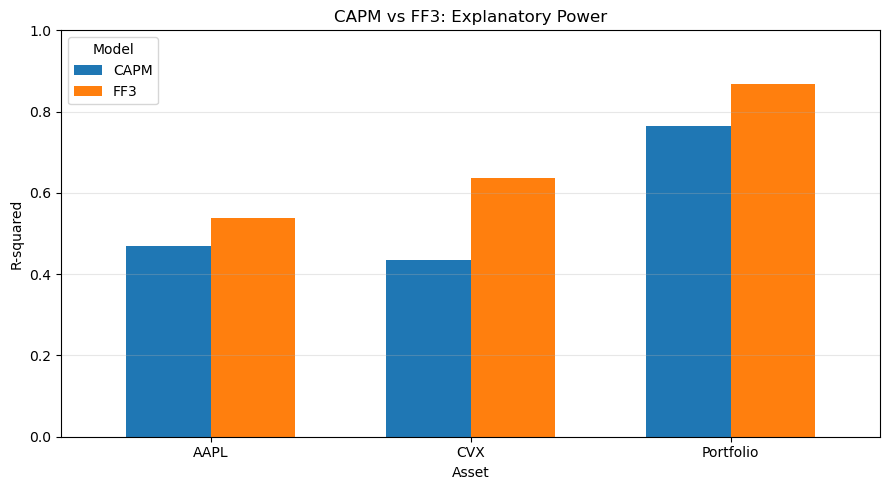

In [4]:
# Compare explanatory power of CAPM and FF3.

r2_comparison = regression_results.pivot(
    index="Asset",
    columns="Model",
    values="R-squared"
)

ax = r2_comparison[["CAPM", "FF3"]].plot.bar(
    figsize=(9, 5),
    width=0.65
)

ax.set_title("CAPM vs FF3: Explanatory Power")
ax.set_xlabel("Asset")
ax.set_ylabel("R-squared")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "T4_CAPM_FF3_r_squared.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



### CAPM vs FF3 Interpretation

The FF3 model improves the portfolio's R-squared from 0.7652 to 0.8677, indicating that market, size, and value factors explain approximately 86.77% of its historical excess-return variation.

The portfolio has a market beta of 0.9382 under FF3, suggesting slightly lower market sensitivity than the broad market. Its negative SMB (-0.4382) and HML (-0.2642) coefficients are statistically significant, indicating large-cap and growth-oriented exposures.

FF3 also improves explanatory power for AAPL (53.76%) and CVX (63.77%). AAPL shows a significant negative HML exposure, while CVX has a significant positive HML exposure, reflecting their different growth and value characteristics.

The portfolio's annualized alpha remains positive at 10.95% under FF3 and is statistically significant (p < 0.05). This supports strong historical risk-adjusted performance.

Overall, the findings provide additional support for the recommended portfolio while highlighting its exposure to large-cap growth stocks.


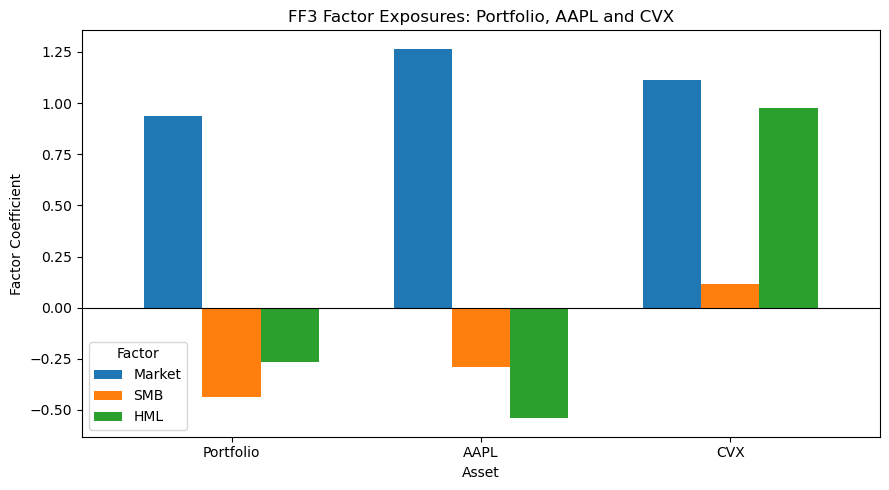

In [5]:
# Compare FF3 factor exposures across the portfolio and two stocks.

ff3_exposures = regression_results[
    regression_results["Model"] == "FF3"
].set_index("Asset")

factor_betas = ff3_exposures[
    ["Market Beta", "SMB Beta", "HML Beta"]
].rename(columns={
    "Market Beta": "Market",
    "SMB Beta": "SMB",
    "HML Beta": "HML"
})

ax = factor_betas.plot.bar(figsize=(9, 5), width=0.7)

ax.set_title("FF3 Factor Exposures: Portfolio, AAPL and CVX")
ax.set_xlabel("Asset")
ax.set_ylabel("Factor Coefficient")
ax.axhline(0, color="black", linewidth=0.8)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Factor")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "T4_FF3_factor_exposures.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



### Factor Exposure Interpretation

All three assets have positive market betas, indicating exposure to broad market movements.

The recommended portfolio has negative SMB (-0.4382) and HML (-0.2642) coefficients, both statistically significant. This indicates a large-cap and growth-oriented investment style.

AAPL also shows a significant growth tilt (HML = -0.5407), while CVX shows a significant value tilt (HML = 0.9784).

These differences highlight the portfolio's factor exposures and help explain how individual securities contribute to its overall risk characteristics.